# 4. Diseño experimental del tercer entregable

## 4.1 Preguntas de investigación

El problema principal sigue siendo el del Entregable 2: predecir, **con la información disponible antes de la llamada**, si el cliente suscribirá el depósito a término, para decidir a quién llamar primero. Este entregable lo amplía en tres direcciones, cada una con una pregunta:

1. **Modelos y balanceo.** ¿Qué combinación de modelo, técnica de balanceo y optimizador discrimina mejor a los clientes que suscriben, medida en el bucle externo de la validación anidada, y supera de forma significativa al modelo base del Entregable 2?
2. **Optimización.** ¿Son la optimización bayesiana y la genética más eficientes que Grid Search y Random Search, es decir, alcanzan mejores soluciones por unidad de presupuesto computacional?
3. **Regresión.** ¿Permite la información previa a la llamada pronosticar su duración mejor que la media histórica?

## 4.2 Explosión combinatoria: cuántos modelos se entrenan

La guía (sección 2) exige un diseño factorial: cada modelo se combina con cada técnica de balanceo (solo en clasificación) y cada combinación se optimiza con cada método. El número de modelos es el producto de las alternativas, no la suma.

In [40]:
part = particion()
assert part.X_tr.index.equals(X_tr.index) and part.X_te.index.equals(X_te.index)  # misma partición del EDA

pliegues = pd.read_parquet(RES / "pliegues.parquet")
historial = pd.read_parquet(RES / "historial.parquet")
oof = pd.read_parquet(RES / "oof.parquet")
maestra = pd.read_parquet(RES / "tabla_maestra.parquet")
corridas = cargar_corridas()
finales = {}
for ruta in sorted((RES / "finales").glob("*_s42.pkl")) + [RES / "finales" / "clf_referencia_e2.pkl"]:
    with open(ruta, "rb") as f:
        r = pickle.load(f)
    finales[f"{r['tarea']}_{r['modelo']}"] = r


print(f"Corridas leídas: {len(corridas)} · combinaciones en la tabla maestra: {len(maestra)} · "
      f"modelos finales: {len(finales)}")

Corridas leídas: 755 · combinaciones en la tabla maestra: 140 · modelos finales: 15


In [41]:
combos = pd.DataFrame(lista_combinaciones(), columns=["tarea", "modelo", "balanceo", "optimizador"])
desglose = pd.DataFrame([
    ("Clasificación (guía)", 7, 4, 4, "7 × 4 × 4", 112),
    ("Regresión (guía)", 7, "no aplica", 4, "7 × 4", 28),
], columns=["Rama", "Modelos", "Balanceo", "Optimizadores", "Operación", "Combinaciones"])
desglose.loc[len(desglose)] = ["Total", "", "", "", "", desglose["Combinaciones"].sum()]
tabla(desglose, indice=False)

conteo = combos.groupby("tarea").size()
assert conteo["clf"] == 112 and conteo["reg"] == 28 and len(combos) == 140 == len(maestra)

n_eval_int = int(pliegues["n_eval"].sum())
n_ajustes = n_eval_int * cfg.K_INTERNO + len(pliegues)
horas_cpu = pliegues["t_opt"].sum() / 3600
interpretar(
    f"El diseño produce {len(combos)} combinaciones, las que exige la guía: {conteo['clf']} de clasificación y "
    f"{conteo['reg']} de regresión. Cada una se evalúa en {cfg.K_EXTERNO} pliegues externos con un presupuesto de "
    f"{cfg.PRESUPUESTO} configuraciones por pliegue, lo que sumó {num(n_eval_int)} evaluaciones internas, "
    f"{num(n_ajustes)} ajustes de modelos y {num(horas_cpu, 1)} horas de CPU de optimización.",
    conectar("En ese sentido,", "Entrenar modelo por modelo era inviable: el *pipeline* se programó como una función "
             "parametrizada (modelo → balanceo → optimizador → pliegue) que se ejecuta en paralelo y guarda cada tarea en "
             "disco, de forma que una corrida interrumpida continúa donde quedó y cada resultado es trazable."),
    conectar("Por ello, se decide", "Registrar todas las combinaciones en una tabla maestra (sección 7.1) y reportar de forma "
             "exhaustiva las más informativas: el mejor representante de cada modelo, los contrastes de balanceo y los de "
             "optimizadores, sin descartar ninguna de la comparación estadística global de la sección 8."))

exportar("desglose", desglose)
exportar("contexto", {"registros": int(len(df)), "registros_limpios": int(len(df_limpio)), "n_tr": int(len(X_tr)),
                      "n_te": int(len(X_te)), "prev_tr": float(y_tr.mean()), "prev_te": float(y_te.mean()),
                      "desde_tr": periodo_tr.iloc[0], "hasta_tr": periodo_tr.iloc[-1], "desde_te": periodo_te.iloc[0],
                      "hasta_te": periodo_te.iloc[-1], "gap": int(GAP), "combinaciones": int(len(combos)),
                      "tareas": int(len(pliegues)), "evaluaciones": n_eval_int, "ajustes": int(n_ajustes),
                      "horas_cpu": float(horas_cpu), "presupuesto": cfg.PRESUPUESTO, "k_ext": cfg.K_EXTERNO,
                      "k_int": cfg.K_INTERNO})


Rama,Modelos,Balanceo,Optimizadores,Operación,Combinaciones
Clasificación (guía),7,4,4,7 × 4 × 4,112
Regresión (guía),7,no aplica,4,7 × 4,28
Total,,,,,140


**Interpretación.** El diseño produce 140 combinaciones, las que exige la guía: 112 de clasificación y 28 de regresión. Cada una se evalúa en 5 pliegues externos con un presupuesto de 20 configuraciones por pliegue, lo que sumó 13 730 evaluaciones internas, 41 890 ajustes de modelos y 29,9 horas de CPU de optimización.

En ese sentido, entrenar modelo por modelo era inviable: el *pipeline* se programó como una función parametrizada (modelo → balanceo → optimizador → pliegue) que se ejecuta en paralelo y guarda cada tarea en disco, de forma que una corrida interrumpida continúa donde quedó y cada resultado es trazable.

Por ello, se decide registrar todas las combinaciones en una tabla maestra (sección 7.1) y reportar de forma exhaustiva las más informativas: el mejor representante de cada modelo, los contrastes de balanceo y los de optimizadores, sin descartar ninguna de la comparación estadística global de la sección 8.

## 4.3 Validación cruzada anidada

Reportar la métrica del mejor modelo con el mismo esquema que se usó para elegirlo produce una estimación optimista (Varma y Simon, 2006; Cawley y Talbot, 2010). Por eso todas las métricas de las secciones 5 a 8 vienen del **bucle externo**:

- **Bucle externo:** `TimeSeriesSplit` de **5 pliegues** sobre el entrenamiento (en orden temporal), con una separación de `GAP` registros (un día de contactos, sección 3) entre ajuste y validación. Cada pliegue externo solo estima el desempeño del modelo ya optimizado.
- **Bucle interno:** dentro del ajuste de cada pliegue externo, `TimeSeriesSplit` de **3 pliegues** con la misma separación, donde cada optimizador evalúa sus configuraciones.
- **Por qué 5 y 3.** El orden temporal impide barajar, y en un `TimeSeriesSplit` el primer ajuste es el más pequeño: con 5 pliegues externos el primero conserva cerca de 5 000 registros y cada bloque de validación tiene alrededor de 5 500, suficientes para estimar el AUC-PR aun con una prevalencia cercana al 5 %. Cinco bloques son además el mínimo razonable para el test de Friedman de la sección 8. En el bucle interno el costo crece con el número de pliegues por cada una de las 20 configuraciones; con 3 pliegues el ajuste interno más pequeño conserva varios cientos de registros y más de una docena de positivos (sección 3.8.2), suficientes para SMOTE, y el costo total es manejable. Un `StratifiedKFold` no se usa porque reintroduciría la fuga temporal documentada en la sección 3.6.
- **Modelo final.** Los hiperparámetros elegidos cambian entre pliegues externos; por eso, para la evaluación en prueba (sección 7.3) se repite la optimización con todo el entrenamiento y la validación temporal de 5 pliegues del Entregable 2, y el conjunto de prueba se usa una sola vez.

,Registros de ajuste,Ajusta hasta,Valida desde,Valida hasta,Registros de validación,% positivos validación,Ajuste interno (mín.–máx.),Validación interna
Pliegue externo,,,,,,,,
1,4 983,2008-05,2008-05,2008-06,5 490,"3,88",741–3 231,1 245
2,10 473,2008-06,2008-06,2008-07,5 490,"6,05",2 112–7 348,2 618
3,15 963,2008-07,2008-07,2008-08,5 490,"5,92",3 486–11 466,3 990
4,21 453,2008-08,2008-08,2008-11,5 490,"5,45",4 857–15 583,5 363
5,26 943,2008-11,2008-11,2009-05,5 490,"14,03",6 231–19 701,6 735


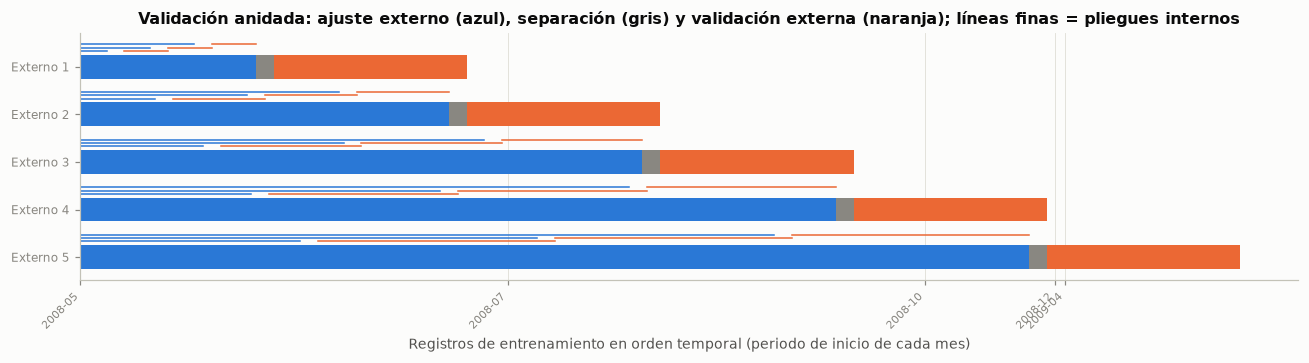

**Interpretación.** El ajuste externo crece de 4 983 a 26 943 registros y cada bloque de validación tiene 5 490. Los primeros pliegues validan dentro de 2008, con una prevalencia entre el 3,9 % y el 6,0 %, y el último valida de 2008-11 a 2009-05 con el 14,0 %.

Hay que tener en cuenta que los pliegues no son intercambiables: el último es el único que se parece a la prueba (2009-2010, prevalencia alta) y los de 2008 miden la capacidad de ordenar clientes en un régimen de tasa baja, donde el Entregable 2 ya mostró que casi ningún modelo discrimina. La media ± desviación estándar entre pliegues mezcla, entonces, variabilidad de muestreo y cambio de régimen.

Por lo anterior, conviene reportar siempre la media ± desviación estándar entre pliegues externos (sección 7.7), usar pruebas de rangos por pliegue, que no suponen bloques intercambiables en escala (sección 8), y contrastar las conclusiones con el conjunto de prueba.

In [42]:
filas = []
for k_, (i_e, i_v) in enumerate(cv_externa(GAP).split(X_tr), start=1):
    internos = list(cv_interna(GAP).split(i_e))
    filas.append({"Pliegue externo": k_, "Registros de ajuste": len(i_e), "Ajusta hasta": periodo_tr.iloc[i_e[-1]],
                  "Valida desde": periodo_tr.iloc[i_v[0]], "Valida hasta": periodo_tr.iloc[i_v[-1]],
                  "Registros de validación": len(i_v), "% positivos validación": 100 * y_tr.iloc[i_v].mean(),
                  "Ajuste interno (mín.–máx.)": f"{num(len(internos[0][0]))}–{num(len(internos[-1][0]))}",
                  "Validación interna": num(len(internos[0][1]))})
esquema_anidado = pd.DataFrame(filas).set_index("Pliegue externo")
tabla(esquema_anidado, dec=2)

fig, ax = plt.subplots(figsize=(12, 3.4))
for k_, (i_e, i_v) in enumerate(cv_externa(GAP).split(X_tr)):
    yk = cfg.K_EXTERNO - k_
    ax.barh(yk, len(i_e), left=0, color=AZUL, height=0.5)
    ax.barh(yk, GAP, left=i_e[-1] + 1, color=GRIS, height=0.5)
    ax.barh(yk, len(i_v), left=i_v[0], color=NARANJA, height=0.5)
    for j, (a_, b_) in enumerate(cv_interna(GAP).split(i_e)):
        ax.plot([a_[0], a_[-1]], [yk + 0.33 + 0.07 * j] * 2, color=AZUL, lw=1)
        ax.plot([b_[0], b_[-1]], [yk + 0.33 + 0.07 * j] * 2, color=NARANJA, lw=1)
ax.set_yticks(range(1, cfg.K_EXTERNO + 1), [f"Externo {cfg.K_EXTERNO - i}" for i in range(cfg.K_EXTERNO)])
cortes = [np.flatnonzero(periodo_tr.to_numpy() == p_)[0] for p_ in periodo_tr.unique()[::2]]
ax.set_xticks(cortes, periodo_tr.unique()[::2], rotation=45, ha="right", fontsize=7.5)
ax.set_xlabel("Registros de entrenamiento en orden temporal (periodo de inicio de cada mes)")
ax.set_title("Validación anidada: ajuste externo (azul), separación (gris) y validación externa (naranja); "
             "líneas finas = pliegues internos")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

interpretar(
    f"El ajuste externo crece de {num(esquema_anidado['Registros de ajuste'].iloc[0])} a "
    f"{num(esquema_anidado['Registros de ajuste'].iloc[-1])} registros y cada bloque de validación tiene "
    f"{num(esquema_anidado['Registros de validación'].iloc[0])}. Los primeros pliegues validan dentro de 2008, con una "
    f"prevalencia entre el {num(esquema_anidado['% positivos validación'].min(), 1)} % y el "
    f"{num(esquema_anidado['% positivos validación'].iloc[:-1].max(), 1)} %, y el último valida de "
    f"{esquema_anidado['Valida desde'].iloc[-1]} a {esquema_anidado['Valida hasta'].iloc[-1]} con el "
    f"{num(esquema_anidado['% positivos validación'].iloc[-1], 1)} %.",
    conectar("Hay que tener en cuenta que", "Los pliegues no son intercambiables: el último es el único que se parece a "
             "la prueba (2009-2010, prevalencia alta) y los de 2008 miden la capacidad de ordenar clientes en un régimen "
             "de tasa baja, donde el Entregable 2 ya mostró que casi ningún modelo discrimina. La media ± desviación "
             "estándar entre pliegues mezcla, entonces, variabilidad de muestreo y cambio de régimen."),
    conectar("Por lo anterior, conviene", "Reportar siempre la media ± desviación estándar entre pliegues externos "
             "(sección 7.7), usar pruebas de rangos por pliegue, que no suponen bloques intercambiables en escala "
             "(sección 8), y contrastar las conclusiones con el conjunto de prueba."))

exportar("esquema_anidado", esquema_anidado.reset_index())


## 4.4 Métrica de validación

**Criterio principal: AUC-PR (precisión promedio, `average_precision`).** Es la métrica que optimiza cada método en el bucle interno y la que ordena las combinaciones. La justificación sale del problema:

- La clase positiva es minoritaria (6,4 % en entrenamiento) y el uso del modelo es priorizar a quién llamar. Un **falso negativo** es un cliente que habría suscrito y no se llama (ingreso perdido); un **falso positivo** es una llamada sin éxito (unos minutos de un asesor). El costo del falso negativo es mayor, lo que favorece métricas centradas en la clase positiva.
- El AUC-ROC premia también el orden entre negativos y es poco sensible al desbalance; la curva precisión-recall describe directamente el compromiso entre encontrar suscriptores (*recall*) y no desperdiciar llamadas (*precision*), y es más informativa en clases desbalanceadas (Saito y Rehmsmeier, 2015).
- No depende de un umbral, así que permite comparar en igualdad de condiciones modelos con y sin balanceo (el balanceo desplaza las probabilidades) y modelos sin probabilidades (la SVM lineal usa su función de decisión).

Junto a ella se reportan accuracy, precision, recall, F1 (con el umbral por defecto del modelo: 0,5 en probabilidad o 0 en la función de decisión), AUC-ROC, Brier y pérdida logarítmica. El *recall* es la métrica de umbral que mejor refleja el costo del negocio, pero optimizarlo directamente favorecería al modelo que llama a todos; por eso se usa como métrica de contraste del balanceo (sección 7.2) y no como criterio de selección.

**Regresión:** RMSE en escala `log1p(duration)` (`neg_root_mean_squared_error`), que penaliza más los errores grandes en la planificación de la carga; el MAE y el error en segundos se reportan como complemento.

## 4.5 Reproducibilidad e ingeniería del *pipeline*

El código está separado en módulos con *docstrings* estilo NumPy para toda función reutilizada, y cada combinación se registra en la tabla maestra con sus hiperparámetros finales por pliegue, métricas del bucle externo, tiempos y semilla.

In [43]:
modulos = pd.DataFrame([
    ("src/bm/config.py", "Semilla global, rutas, variables, presupuesto y nombres de modelos, balanceos y optimizadores"),
    ("src/bm/datos.py", "Carga, reconstrucción del calendario, partición cronológica y esquemas de validación"),
    ("src/bm/preprocesamiento.py", "ColumnTransformer del Entregable 2 (escalado, log1p, pdays = 999, one-hot)"),
    ("src/bm/modelos.py", "Pipelines de imblearn: preprocesamiento → balanceo → modelo; equivalentes de class_weight"),
    ("src/bm/espacios.py", "Espacios de búsqueda compartidos y rejillas de Grid Search"),
    ("src/bm/optimizadores.py", "Evaluador común con presupuesto y registro anytime; Grid, Random, Optuna y DEAP"),
    ("src/bm/anidada.py", "Validación anidada por tarea, Successive Halving, consolidación de la tabla maestra"),
    ("src/bm/evaluacion.py", "Finalistas en prueba, calibración (Platt, isotónica, mensual) y diagnóstico de residuos"),
    ("src/bm/estadistica.py", "Friedman, Nemenyi, DeLong, BCa, Cliff, MCS, GW, Clark-West, DM-HLN, SPA"),
    ("src/bm/computacional.py", "Complejidad, escalamiento, paralelización y perfilamiento"),
    ("scripts/ejecutar_experimentos.py", "Ejecución paralela y reanudable de las 700 tareas (140 combinaciones × 5 pliegues)"),
    ("scripts/ejecutar_finales.py", "Finalistas, recalibración, sensibilidad a semillas y experimentos computacionales"),
], columns=["Módulo", "Responsabilidad"])
tabla(modulos, indice=False)
print("Columnas de la tabla maestra (resultados/tabla_maestra.csv y .parquet):")
print(", ".join(maestra.columns))
print(f"\nSemilla registrada en todas las combinaciones: {sorted(maestra['seed'].unique())}")

Módulo,Responsabilidad
src/bm/config.py,"Semilla global, rutas, variables, presupuesto y nombres de modelos, balanceos y optimizadores"
src/bm/datos.py,"Carga, reconstrucción del calendario, partición cronológica y esquemas de validación"
src/bm/preprocesamiento.py,"ColumnTransformer del Entregable 2 (escalado, log1p, pdays = 999, one-hot)"
src/bm/modelos.py,Pipelines de imblearn: preprocesamiento → balanceo → modelo; equivalentes de class_weight
src/bm/espacios.py,Espacios de búsqueda compartidos y rejillas de Grid Search
src/bm/optimizadores.py,"Evaluador común con presupuesto y registro anytime; Grid, Random, Optuna y DEAP"
src/bm/anidada.py,"Validación anidada por tarea, Successive Halving, consolidación de la tabla maestra"
src/bm/evaluacion.py,"Finalistas en prueba, calibración (Platt, isotónica, mensual) y diagnóstico de residuos"
src/bm/estadistica.py,"Friedman, Nemenyi, DeLong, BCa, Cliff, MCS, GW, Clark-West, DM-HLN, SPA"
src/bm/computacional.py,"Complejidad, escalamiento, paralelización y perfilamiento"


Columnas de la tabla maestra (resultados/tabla_maestra.csv y .parquet):
tarea, modelo, balanceo, optimizador, accuracy_media, precision_media, recall_media, f1_media, auc_media, auc_pr_media, brier_media, log_loss_media, rmse_media, mae_media, r2_media, rmse_seg_media, mae_seg_media, accuracy_de, precision_de, recall_de, f1_de, auc_de, auc_pr_de, brier_de, log_loss_de, rmse_de, mae_de, r2_de, rmse_seg_de, mae_seg_de, n_pliegues, n_eval_total, t_opt_total, t_por_eval, t_fit_medio, t_pred_medio, puntaje_interno_medio, seed, params_por_pliegue

Semilla registrada en todas las combinaciones: [np.int64(42)]
